In [1]:
import sys

sys.path.append("../src")
import torch
from datasets.bird_audio import BirdAudio
from models.vae import VAE
from processing.audio import log_mel_to_waveform
from IPython.display import Audio, display
from torchvision.transforms.functional import to_pil_image

In [2]:
CHECKPOINT_PATH = "../models/contrastive_audio_vae/1785588335498284773/contrastive_audio_vae_final.tar"
DATASET_PATH = "../data/iNaturalistPrunedPreprocessedAudio"

checkpoint = torch.load(CHECKPOINT_PATH)
vae_parameters = checkpoint["model_parameters"]
train_parameters = checkpoint["train_parameters"]
train_parameters.device = "cuda:1"

/tmp/ipykernel_1345992/1858654960.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_PATH)


# Visual Inspection of Outputs

In [3]:
train_dataset = BirdAudio(DATASET_PATH, split="train", from_spectrogram=True)
val_dataset = BirdAudio(DATASET_PATH, split="val", from_spectrogram=True)

In [4]:
vae = VAE(vae_parameters)
vae.load_state_dict(checkpoint["model_state_dict"])
vae = vae.to(train_parameters.device)

In [5]:
vae.eval()
outputs = vae(
    torch.unsqueeze(val_dataset[5][0].to(train_parameters.device), 0)
)

In [6]:
outputs.original_input.shape

torch.Size([1, 1, 128, 313])

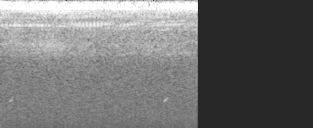

In [7]:
display(to_pil_image(outputs.original_input.squeeze().clamp(0, 1)))

In [8]:
display(
    Audio(
        log_mel_to_waveform(outputs.original_input.cpu().squeeze())[0].numpy(),
        rate=16000,
    )
)

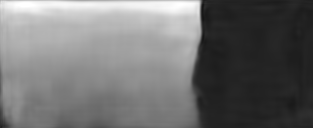

In [9]:
display(to_pil_image(outputs.reconstructed.squeeze().clamp(0, 1)))

In [10]:
display(
    Audio(
        log_mel_to_waveform(outputs.reconstructed.detach().cpu().squeeze())[0].numpy(),
        rate=16000,
    )
)

# Plotting Loss Curves

In [17]:
%matplotlib inline

import pandas as pd
import seaborn as sns

print(checkpoint['train_losses'].keys())

epochs = len(checkpoint['train_losses']['total_loss'])
losses = pd.DataFrame({
    "total_losses": checkpoint['train_losses']['total_loss'] + checkpoint['val_losses']['total_loss'],
    "reconstruction_losses": checkpoint['train_losses']['reconstruction_loss'] + checkpoint['val_losses']['reconstruction_loss'],
    "kl_losses": checkpoint['train_losses']['kl_loss'] + checkpoint['val_losses']['kl_loss'],
    "latent_mean_mae_loss": checkpoint['train_losses']['latent_mean_mae_loss'] + checkpoint['val_losses']['latent_mean_mae_loss'],
    "latent_logvar_mae_loss": checkpoint['train_losses']['latent_logvar_mae_loss'] + checkpoint['val_losses']['latent_logvar_mae_loss'],
    "contrastive_loss": checkpoint['train_losses']['contrastive_loss'] + checkpoint['val_losses']['contrastive_loss'],
    "split": ["train"] * epochs + ["val"] * epochs,
    "epoch": list(range(epochs)) + list(range(epochs))
})

dict_keys(['total_loss', 'reconstruction_loss', 'kl_loss', 'latent_mean_mae_loss', 'latent_logvar_mae_loss', 'contrastive_loss'])


<Axes: xlabel='epoch', ylabel='total_losses'>

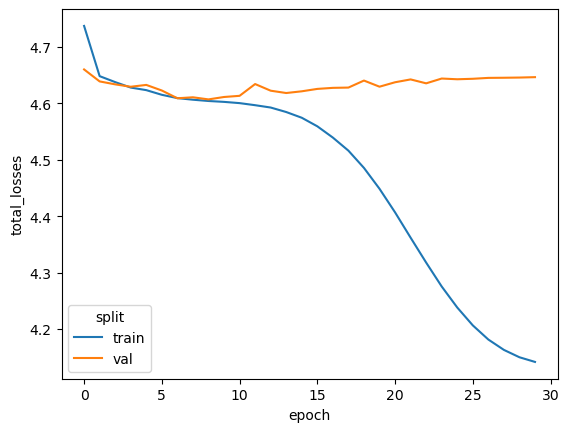

In [18]:
sns.lineplot(
    losses,
    x="epoch",
    y="total_losses",
    hue="split"
)

<Axes: xlabel='epoch', ylabel='reconstruction_losses'>

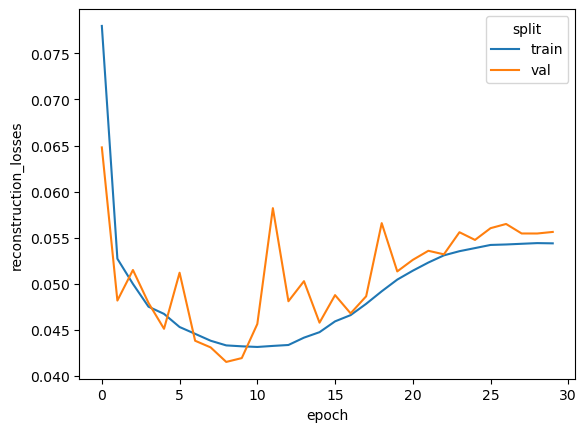

In [19]:
sns.lineplot(
    losses,
    x="epoch",
    y="reconstruction_losses",
    hue="split"
)

<Axes: xlabel='epoch', ylabel='kl_losses'>

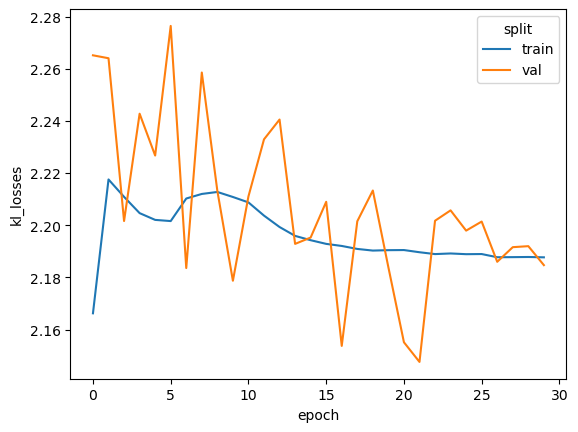

In [20]:
sns.lineplot(
    losses,
    x="epoch",
    y="kl_losses",
    hue="split"
)

<Axes: xlabel='epoch', ylabel='latent_mean_mae_loss'>

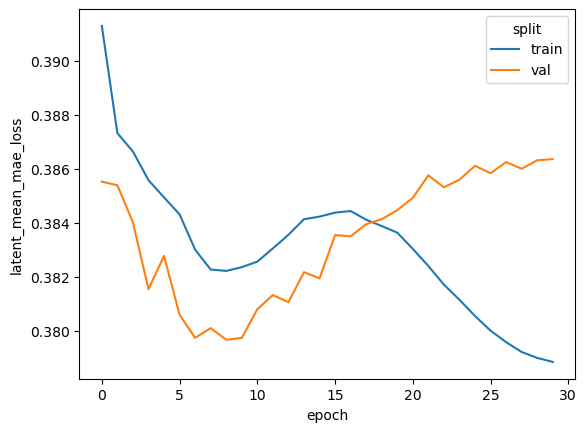

In [21]:
sns.lineplot(
    losses,
    x="epoch",
    y="latent_mean_mae_loss",
    hue="split"
)

<Axes: xlabel='epoch', ylabel='latent_logvar_mae_loss'>

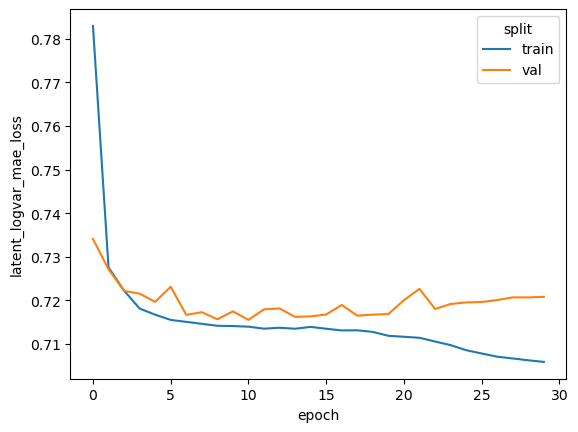

In [22]:
sns.lineplot(
    losses,
    x="epoch",
    y="latent_logvar_mae_loss",
    hue="split"
)

<Axes: xlabel='epoch', ylabel='contrastive_loss'>

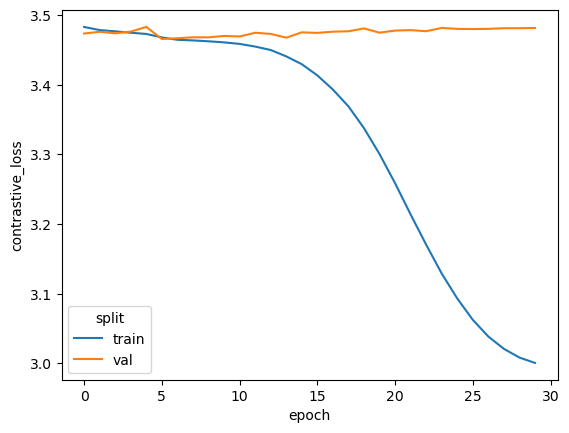

In [23]:
sns.lineplot(
    losses,
    x="epoch",
    y="contrastive_loss",
    hue="split"
)